In [1]:
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams["figure.dpi"] = 110
N_KMEANS = 30_000   # flows used to fit K-Means
N_AGG = 6_000       # agglomerative clustering is O(n^2) in memory: a subset of the K-Means sample
N_TSNE = 3_000

## 1. Load and audit

In [2]:
import glob, os

def find_data(name="train_test_network.csv"):
    """Kaggle: any attached dataset that contains the file. Locally: the repo's data/raw folder."""
    patterns = [f"/kaggle/input/**/{name}", f"/kaggle/input/**/{name.title()}", f"/kaggle/input/**/Train_Test_Network.csv",
                f"../data/raw/TON_IoT/{name}", f"data/raw/TON_IoT/{name}", f"../data/raw/toniot/{name}", f"data/raw/toniot/{name}"]
    for p in patterns:
        hits = glob.glob(p, recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(
        "train_test_network.csv not found. On Kaggle: Add Input -> search 'TON_IoT train_test_network' and attach it. "
        "Locally: put the file in data/raw/TON_IoT/.")

DATA_PATH = find_data()
ON_KAGGLE = DATA_PATH.startswith("/kaggle/")
OUT_DIR = "/kaggle/working" if ON_KAGGLE else "../results"
FIG_DIR = os.path.join(OUT_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("data:", DATA_PATH)
print("outputs:", OUT_DIR)

data: ../data/raw/TON_IoT/train_test_network.csv
outputs: ../results


In [3]:
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("shape:", raw.shape, "| missing values:", int(raw.isna().sum().sum()), "| duplicates:", int(raw.duplicated().sum()))
df = raw.drop_duplicates(ignore_index=True)
print("after dropping duplicates:", df.shape)

shape: (211043, 44) | missing values: 0 | duplicates: 20569


after dropping duplicates: (190474, 44)


## 2. Features (labels removed)

Same feature engineering as the classification notebook: `log1p` on byte, packet and duration counts, average packet size each way, whether the destination replied, a top-10 destination-port bucket, and one-hot encoded protocol, service, connection state and DNS/SSL/HTTP flags. Machine identifiers and free text are dropped.

`type` and `label` are set aside and **never** passed to a clustering algorithm.

Distances are only meaningful if features share a scale: numeric features are standardised; one-hot columns stay 0/1 so a rare category cannot dominate the distance.

In [4]:
# Columns that identify a machine or hold free text. A model that sees them can memorise
# which testbed host ran which attack instead of learning what the traffic looks like.
IDENTIFIERS = ["src_ip", "dst_ip", "src_port"]
FREE_TEXT = ["dns_query", "ssl_subject", "ssl_issuer", "http_uri", "http_user_agent", "http_orig_mime_types",
             "http_resp_mime_types", "http_trans_depth", "http_version", "weird_addl"]
# `label` is 0 exactly when `type` is normal, so it is the answer in disguise.
TARGET, LEAKY_TARGET = "type", "label"

# Heavy-tailed counts: log1p squeezes values that span several orders of magnitude.
LOG_COLS = ["duration", "src_bytes", "dst_bytes", "missed_bytes", "src_pkts", "dst_pkts", "src_ip_bytes",
            "dst_ip_bytes", "http_request_body_len", "http_response_body_len"]
# Low-cardinality codes and flags, one-hot encoded. Numeric codes such as dns_qtype are labels, not quantities.
CAT_COLS = ["proto", "service", "conn_state", "dns_AA", "dns_RD", "dns_RA", "dns_rejected", "ssl_version",
            "ssl_cipher", "ssl_resumed", "ssl_established", "http_method", "weird_name", "weird_notice",
            "dns_qtype", "dns_rcode", "dns_qclass", "http_status_code", "dst_port_bucket"]


def build_features(d, top_ports):
    """Engineered feature table. `top_ports` must come from the training rows only."""
    X = pd.DataFrame(index=d.index)
    for c in LOG_COLS:
        X[c] = np.log1p(d[c].clip(lower=0))
    # engineered: average packet size each way (scans and floods send tiny, uniform packets)
    X["bytes_per_src_pkt"] = np.log1p(d["src_bytes"] / d["src_pkts"].replace(0, np.nan)).fillna(0)
    X["bytes_per_dst_pkt"] = np.log1p(d["dst_bytes"] / d["dst_pkts"].replace(0, np.nan)).fillna(0)
    # engineered: did the other side answer at all? (S0/REJ scans often get no reply)
    X["has_reply"] = (d["dst_pkts"] > 0).astype(int)
    # engineered: the ten most common destination ports keep their number, the rest become "other"
    port = d["dst_port"].where(d["dst_port"].isin(top_ports))
    X["dst_port_bucket"] = port.map(lambda p: "other" if pd.isna(p) else str(int(p)))
    for c in CAT_COLS:
        if c != "dst_port_bucket":
            X[c] = d[c].astype(str)
    return X

In [5]:
sample = df.sample(n=min(N_KMEANS, len(df)), random_state=RANDOM_STATE).reset_index(drop=True)
truth = sample[TARGET].values                     # kept aside for interpretation only
top_ports = sample["dst_port"].value_counts().head(10).index
F = build_features(sample, top_ports)
num_cols = [c for c in F.columns if pd.api.types.is_numeric_dtype(F[c])]
cat_cols = [c for c in F.columns if c not in num_cols]
pre = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), cat_cols),
])
X = pre.fit_transform(F)
print("feature matrix:", X.shape)
agg_idx = np.random.RandomState(RANDOM_STATE).choice(len(X), N_AGG, replace=False)

feature matrix: (30000, 87)


## 3. K-Means
### 3.1 Choosing k: elbow curve
Inertia (within-cluster sum of squares) always falls as k grows; the *elbow* is where adding a cluster stops paying off. Silhouette is shown alongside as a second opinion.

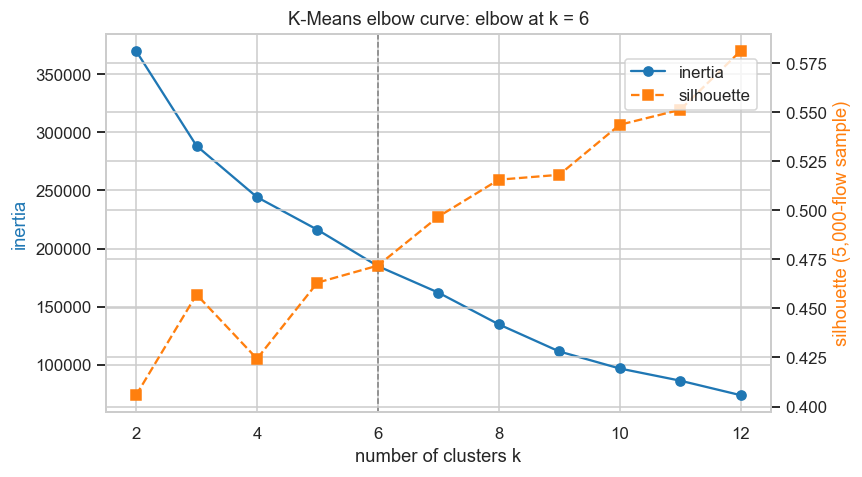

,k,inertia,silhouette
0,2,369908.6657,0.4058
1,3,288323.5493,0.4571
2,4,244245.0763,0.4244
3,5,216191.0651,0.4631
4,6,184931.7160,0.4718
5,7,162164.9049,0.4968
6,8,134867.8437,0.5156
7,9,111567.0027,0.5181
8,10,96918.5590,0.5436
9,11,86458.7199,0.5512


In [6]:
ks = range(2, 13)
elbow = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    elbow.append({"k": k, "inertia": km.inertia_,
                  "silhouette": silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE)})
elbow = pd.DataFrame(elbow)

# elbow = the k furthest below the straight line joining the first and last points
line = np.interp(elbow.k, [elbow.k.iloc[0], elbow.k.iloc[-1]], [elbow.inertia.iloc[0], elbow.inertia.iloc[-1]])
K_BEST = int(elbow.k.iloc[np.argmax(line - elbow.inertia)])

fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.plot(elbow.k, elbow.inertia, "o-", color="tab:blue", label="inertia")
ax1.axvline(K_BEST, color="grey", ls="--", lw=1)
ax1.set_xlabel("number of clusters k"); ax1.set_ylabel("inertia", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(elbow.k, elbow.silhouette, "s--", color="tab:orange", label="silhouette")
ax2.set_ylabel("silhouette (5,000-flow sample)", color="tab:orange")
ax1.set_title(f"K-Means elbow curve: elbow at k = {K_BEST}")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88)); plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "clu_01_elbow.png"), bbox_inches="tight"); plt.show()
elbow.round(4)

> **Observation (write in your own words):** Is the elbow clear? Do inertia and silhouette point to the same k?
>
> _…_

In [7]:
kmeans = KMeans(n_clusters=K_BEST, n_init=20, random_state=RANDOM_STATE).fit(X)
km_labels = kmeans.labels_
print("cluster sizes:", np.bincount(km_labels).tolist())

cluster sizes: [6524, 10625, 5386, 1747, 4, 5714]


## 4. Agglomerative (hierarchical) clustering
### 4.1 Comparing linkage strategies
Fitted on a 6,000-flow subset (the full pairwise-distance matrix of 30,000 flows would not fit in memory). Single linkage tends to chain everything into one giant cluster, so cluster balance is reported next to the scores.

In [8]:
Xa = X[agg_idx]
link_rows, AGG = [], {}
for linkage_name in ["ward", "complete", "average", "single"]:
    t0 = time.time()
    lab = AgglomerativeClustering(n_clusters=K_BEST, linkage=linkage_name).fit_predict(Xa)
    AGG[linkage_name] = lab
    link_rows.append({"linkage": linkage_name, "silhouette": silhouette_score(Xa, lab), "davies_bouldin": davies_bouldin_score(Xa, lab),
                      "calinski_harabasz": calinski_harabasz_score(Xa, lab),
                      "largest cluster share": np.bincount(lab).max() / len(lab), "time (s)": time.time() - t0})
links = pd.DataFrame(link_rows).set_index("linkage")
# best linkage: highest silhouette among the ones that do not put 90%+ of flows into a single cluster
usable = links[links["largest cluster share"] < 0.9]
BEST_LINKAGE = (usable if len(usable) else links)["silhouette"].idxmax()
print("chosen linkage:", BEST_LINKAGE)
links.round(4)

chosen linkage: ward


,silhouette,davies_bouldin,calinski_harabasz,largest cluster share,time (s)
linkage,,,,,
ward,0.4622,0.7524,2844.7651,0.3707,3.3969
complete,0.5813,0.2994,490.8967,0.9897,3.4550
average,0.6799,0.3657,386.1760,0.9982,3.5703
single,0.6798,0.2671,384.7117,0.9983,2.9009


### 4.2 Dendrogram

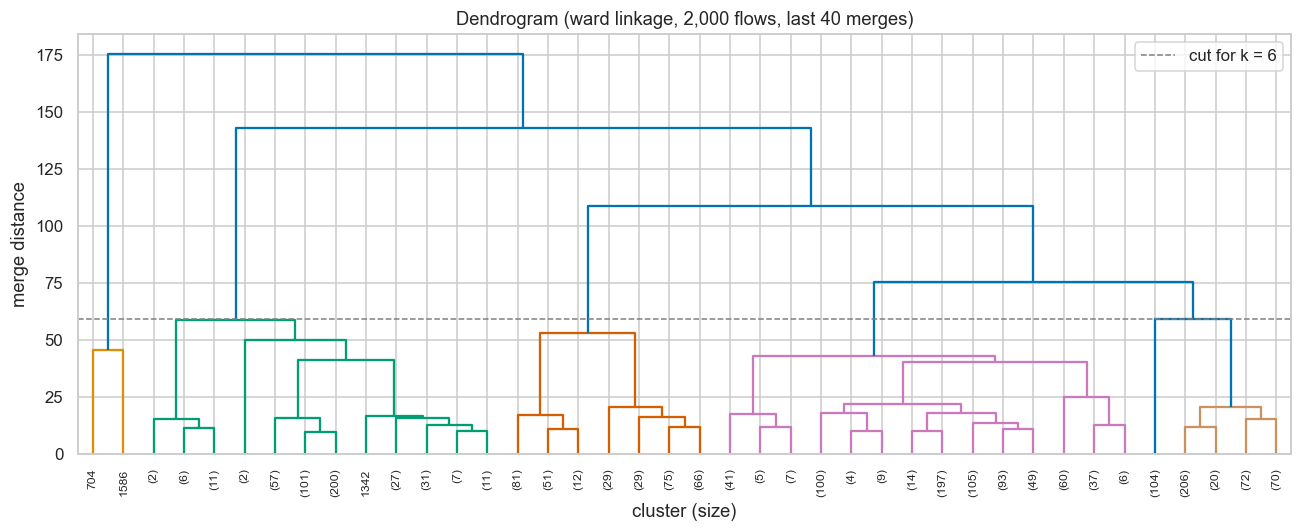

In [9]:
den_idx = agg_idx[:2000]
method = BEST_LINKAGE
Z = linkage(X[den_idx], method=method)
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=40, show_leaf_counts=True, leaf_rotation=90, ax=ax, color_threshold=Z[-(K_BEST - 1), 2])
ax.axhline(Z[-(K_BEST - 1), 2], color="grey", ls="--", lw=1, label=f"cut for k = {K_BEST}")
ax.set_title(f"Dendrogram ({method} linkage, 2,000 flows, last 40 merges)"); ax.set_xlabel("cluster (size)"); ax.set_ylabel("merge distance")
ax.legend(); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "clu_02_dendrogram.png"), bbox_inches="tight"); plt.show()
agg_labels = AGG[BEST_LINKAGE]

> **Observation (write in your own words):** Where would you cut the dendrogram, and does that agree with the elbow?
>
> _…_

## 5. Evaluation metrics
Both algorithms scored on the **same 6,000 flows** so the numbers are comparable. Silhouette (higher is better, −1 to 1), Davies-Bouldin (lower is better), Calinski-Harabasz (higher is better).

In [10]:
def scores(Xs, lab):
    return {"Silhouette ↑": silhouette_score(Xs, lab), "Davies-Bouldin ↓": davies_bouldin_score(Xs, lab),
            "Calinski-Harabasz ↑": calinski_harabasz_score(Xs, lab), "clusters": len(set(lab))}
metrics = pd.DataFrame({
    f"K-Means (k={K_BEST})": scores(Xa, km_labels[agg_idx]),
    f"Agglomerative ({BEST_LINKAGE}, k={K_BEST})": scores(Xa, agg_labels),
}).T
metrics.to_csv(os.path.join(OUT_DIR, "clustering_metrics_ton_iot.csv"))
metrics.round(4)

,Silhouette ↑,Davies-Bouldin ↓,Calinski-Harabasz ↑,clusters
K-Means (k=6),0.4741,0.7426,2953.6417,6.0
"Agglomerative (ward, k=6)",0.4622,0.7524,2844.7651,6.0


### 5.1 Stability check (5 runs)
Clustering has no labels, so ordinary cross-validation does not apply. Instead K-Means is refitted on **5 different random samples** of 20,000 flows (5 seeds) and the metrics are compared. Small spreads, and high agreement (ARI) between runs on the same flows, mean the clusters are a property of the data rather than of one lucky sample.

In [11]:
from itertools import combinations
X_all = pre.transform(build_features(df, top_ports))
probe = np.random.RandomState(0).choice(len(X_all), 5000, replace=False)     # the same flows, labelled by every run
runs, probe_labels = [], []
for seed in range(5):
    idx = np.random.RandomState(seed + 1).choice(len(X_all), 20_000, replace=False)
    km_s = KMeans(n_clusters=K_BEST, n_init=10, random_state=seed).fit(X_all[idx])
    lab = km_s.labels_
    ev = np.random.RandomState(seed).choice(len(idx), 5000, replace=False)
    runs.append({"run": seed + 1, "Silhouette": silhouette_score(X_all[idx][ev], lab[ev]),
                 "Davies-Bouldin": davies_bouldin_score(X_all[idx], lab), "Calinski-Harabasz": calinski_harabasz_score(X_all[idx], lab)})
    probe_labels.append(km_s.predict(X_all[probe]))
runs = pd.DataFrame(runs).set_index("run")
pair_ari = [adjusted_rand_score(a, b) for a, b in combinations(probe_labels, 2)]
summary_runs = runs.agg(["mean", "std"])
summary_runs.to_csv(os.path.join(OUT_DIR, "clustering_stability_ton_iot.csv"))
print(f"agreement between runs on the same 5,000 flows: ARI {np.mean(pair_ari):.3f} ± {np.std(pair_ari):.3f} (10 pairs)")
pd.concat([runs, summary_runs]).round(4)

agreement between runs on the same 5,000 flows: ARI 0.943 ± 0.043 (10 pairs)


,Silhouette,Davies-Bouldin,Calinski-Harabasz
1,0.4725,0.9696,7343.7396
2,0.4715,0.7948,8129.4738
3,0.4793,0.7749,8418.0674
4,0.4646,0.7896,8046.4637
5,0.4491,0.8515,8485.3803
mean,0.4674,0.8361,8084.6249
std,0.0115,0.0801,453.9184


> **Observation (write in your own words):** Are the metrics stable across the five runs? What would a low ARI between runs mean?
>
> _…_

### 5.2 Tuning summary
The clustering hyperparameters were searched, not fixed: `k` over 2 to 12 by the elbow (Section 3) and the linkage over four strategies (Section 4.1).

## 6. Visualising the clusters
### 6.1 PCA (2 components), one plot per algorithm

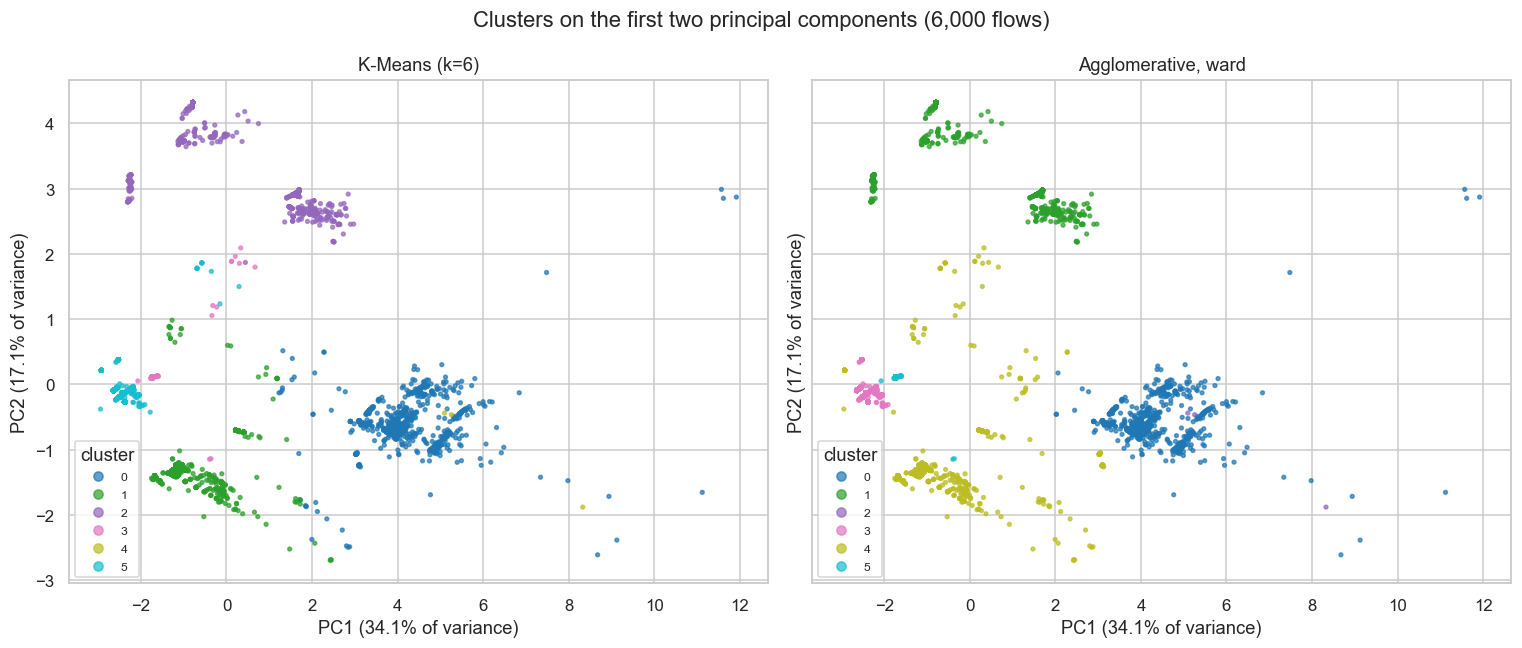

In [12]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
P = pca.transform(Xa)
ev = pca.explained_variance_ratio_
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for ax, (title, lab) in zip(axes, [(f"K-Means (k={K_BEST})", km_labels[agg_idx]), (f"Agglomerative, {BEST_LINKAGE}", agg_labels)]):
    sc = ax.scatter(P[:, 0], P[:, 1], c=lab, cmap="tab10", s=6, alpha=0.7)
    ax.set_title(title); ax.set_xlabel(f"PC1 ({ev[0]:.1%} of variance)"); ax.set_ylabel(f"PC2 ({ev[1]:.1%} of variance)")
    ax.legend(*sc.legend_elements(), title="cluster", fontsize=8, loc="best")
plt.suptitle("Clusters on the first two principal components (6,000 flows)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "clu_03_pca.png"), bbox_inches="tight"); plt.show()

### 6.2 t-SNE (K-Means)
t-SNE preserves local neighbourhoods rather than global distances, so separated islands are meaningful but distances between them are not. Shown next to the true traffic type, which the algorithm never saw.

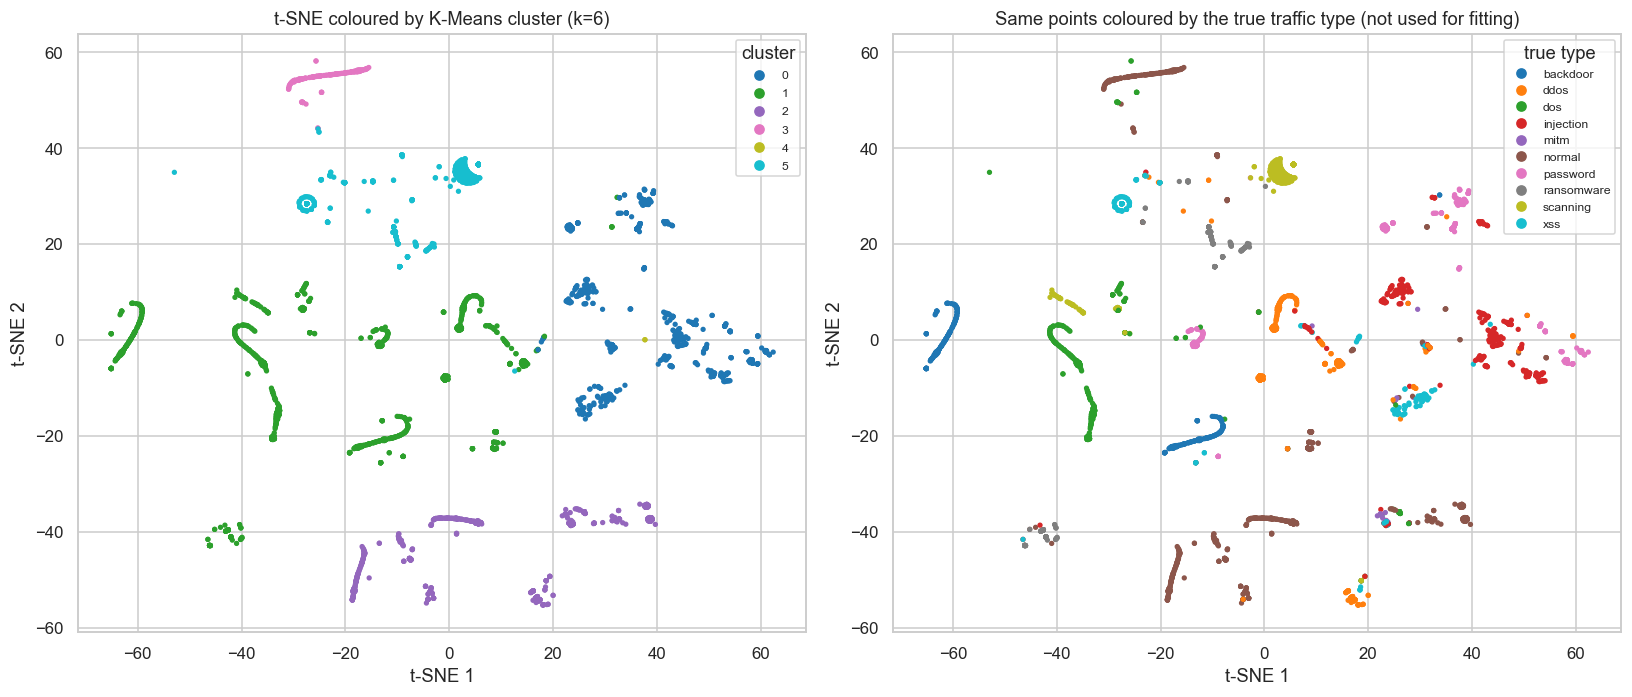

In [13]:
ts_idx = agg_idx[:N_TSNE]
T = TSNE(n_components=2, perplexity=40, init="pca", random_state=RANDOM_STATE).fit_transform(X[ts_idx])
fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
sc = axes[0].scatter(T[:, 0], T[:, 1], c=km_labels[ts_idx], cmap="tab10", s=6)
axes[0].legend(*sc.legend_elements(), title="cluster", fontsize=8)
axes[0].set_title(f"t-SNE coloured by K-Means cluster (k={K_BEST})")
types = pd.Categorical(truth[ts_idx])
sc2 = axes[1].scatter(T[:, 0], T[:, 1], c=types.codes, cmap="tab10", s=6)
axes[1].legend(sc2.legend_elements()[0], list(types.categories), title="true type", fontsize=8)
axes[1].set_title("Same points coloured by the true traffic type (not used for fitting)")
for ax in axes: ax.set_xlabel("t-SNE 1"); ax.set_ylabel("t-SNE 2")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "clu_04_tsne.png"), bbox_inches="tight"); plt.show()

## 7. What is inside each cluster (labels used only now)

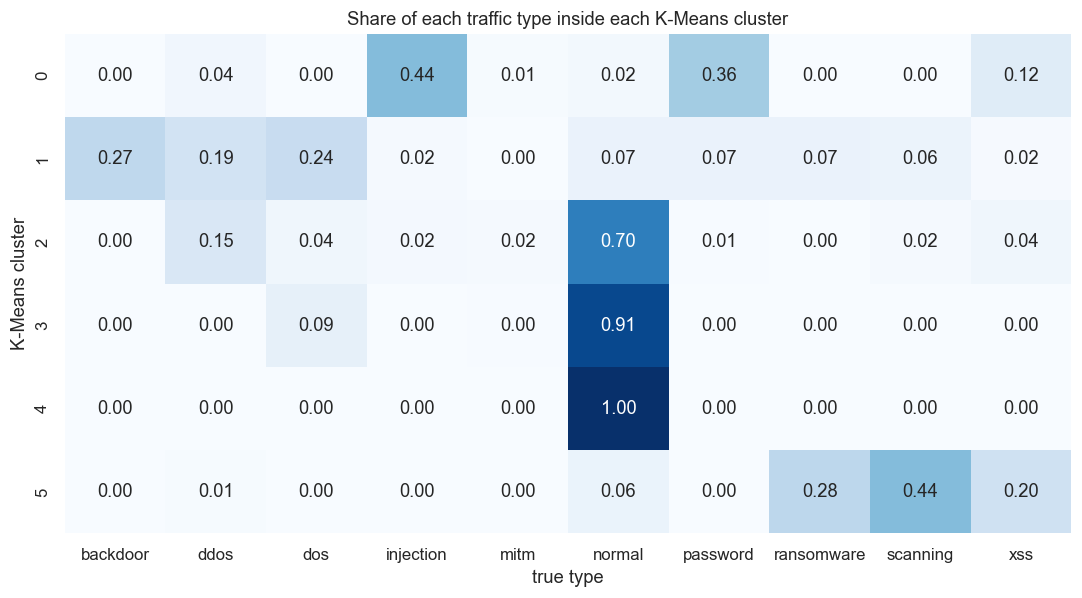

,ARI vs type,NMI vs type,size of largest cluster
K-Means,0.2589,0.4190,0.3542
Agglomerative (ward),0.2487,0.4162,0.3707


In [14]:
comp = pd.crosstab(pd.Series(km_labels, name="K-Means cluster"), pd.Series(truth, name="true type"), normalize="index")
fig, ax = plt.subplots(figsize=(10, 0.6 * K_BEST + 2))
sns.heatmap(comp, annot=True, fmt=".2f", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Share of each traffic type inside each K-Means cluster")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "clu_05_composition.png"), bbox_inches="tight"); plt.show()

agree = pd.DataFrame({
    "ARI vs type": [adjusted_rand_score(truth, km_labels), adjusted_rand_score(truth[agg_idx], agg_labels)],
    "NMI vs type": [normalized_mutual_info_score(truth, km_labels), normalized_mutual_info_score(truth[agg_idx], agg_labels)],
    "size of largest cluster": [np.bincount(km_labels).max() / len(km_labels), np.bincount(agg_labels).max() / len(agg_labels)],
}, index=["K-Means", f"Agglomerative ({BEST_LINKAGE})"])
agree.round(4)

> **Observation (write in your own words):** Which clusters are almost pure (one traffic type), and which mix attacks with normal traffic? What behaviour does each cluster seem to capture?
>
> _…_

In [15]:
pd.DataFrame({"flow": np.arange(len(km_labels)), "kmeans_cluster": km_labels, "type": truth}).to_csv(
    os.path.join(OUT_DIR, "clustering_assignments_ton_iot.csv"), index=False)
print("saved to", OUT_DIR)

saved to ../results
